Authors:
- Cezary Suchorski 160310
- Bartosz Tarnachowicz 160304

Code repo: https://github.com/csuchorski/evolutionary_computation

# Local search for the Hamiltonian cycle through a selected half of the nodes

**Evolutionary Computation · Laboratory 3**

This notebook is the report. The optimisation engine is shared by all three
laboratories (`engine/`), reads the instances from `data/`, builds the distance
matrix once and writes machine-readable results (`lab3/results/*.csv`).
Everything shown below — tables, distributions, local-search diagnostics,
2-D visualisations, best-tour listings and the discussion — is produced here in
Python from those files. The heuristic methods of Laboratories 1 and 2 are
kept unchanged and included in every results table; Laboratory 3 adds eight
local-search variants.

| | |
|---|---|
| Instances | `TSPA.csv`, `TSPB.csv` — 200 nodes each |
| Selected nodes | *k* = ⌈*n*/2⌉ = 100 |
| Methods | 8 previous heuristics + 8 local-search variants = 16 |
| Solutions | 200 per method and instance |
| Seed | 12345 |
| Engine | `g++ -O2 -std=c++17`, shared `engine/` directory |

## 1. Problem description

Each instance describes **n = 200** points in the plane. Point *i* has coordinates (*x<sub>i</sub>*, *y<sub>i</sub>*) and an integer cost *c<sub>i</sub>*. We must select exactly **k = ⌈n/2⌉ = 100** nodes and arrange them in one closed tour that visits every selected node exactly once, minimising

<p align="center">
F(T) = &Sigma;<sub>i=0</sub><sup>k&minus;1</sup> [ c<sub>t<sub>i</sub></sub> + d(t<sub>i</sub>, t<sub>i+1</sub>) ],&nbsp;&nbsp;&nbsp; t<sub>k</sub> = t<sub>0</sub>,
</p>

where d(i, j) is the Euclidean distance rounded to the nearest integer. Both
terms matter: a cheap node far from the route may cost more in travel than it
saves, and a geometrically convenient node may be expensive. Because |T| is
fixed, the node-cost term is an additive penalty of constant size.

## 2. Data and distance matrix

The files contain one row per node with the fields `x;y;cost`. The distance
matrix is computed **once, immediately after reading**:

<p align="center">
d(i, j) = round( &radic;( (x<sub>i</sub> &minus; x<sub>j</sub>)<sup>2</sup> + (y<sub>i</sub> &minus; y<sub>j</sub>)<sup>2</sup> ) )
</p>

with `std::llround` (half away from zero). The optimisation routines receive only
`d[][]` and `cost[]`; the coordinates are used by this notebook for plotting
only. The two supplied instances are Euclidean, so d(i, j) = d(j, i). The
shared loader also records this symmetry; the 2-opt delta uses it and the engine
contains an exact directed fallback.

## 3. Algorithms

Every method returns a sequence `T` of exactly `k` distinct nodes. The
heuristic methods of Laboratories 1 and 2 remain unchanged and are included
as a reference:

- **Random** — a uniformly random `k`-subset in random order.
- **NN append at end** — grow an open path by appending the node minimising
  `cost[j] + d[last][j]`, then close it.
- **NN any position** — insert the best node at the front, inside or at the end,
  using the full insertion delta.
- **Greedy cycle** — keep a closed cycle and insert the `(node, edge)` pair
  minimising `cost[j] + d[a][j] + d[j][b] - d[a][b]`.
- **2-regret** — insert the unused node with the largest gap between its
  second-best and best insertion delta, on the open-path or closed-cycle base.
- **Weighted sum** — mix normalised regret and normalised best change, again on
  both bases.

Laboratory 3 starts from one of two solutions and improves it with local
search. The search must use **deltas of the objective function**: no neighbour
tour is constructed explicitly and the objective is never recomputed from
scratch while a move is evaluated. The final tour is re-evaluated and validated
once, after the search stops. No previous-iteration deltas and no candidate-list
restriction of the neighbourhood are used; the greedy variant's temporary
descriptor list always contains the whole mixed neighbourhood and is rebuilt
after every accepted move.

### 3.1 Starting solutions

Two starts are used:

1. **Random start** — the Laboratory-1 random heuristic: choose `k` distinct
   nodes uniformly and shuffle them. Two hundred independent starts are used.
2. **Greedy start** — the Laboratory-1 **greedy cycle** with a given start node.
   It was the best heuristic from Laboratories 1–2 on average across the two
   instances. Two hundred runs use start nodes `0, 1, …, 199`, so every node is
   used exactly once.

The start is evaluated once by `EVALUATE(T)`; the local search then works only
with the current tour and its objective value.

### 3.2 Delta-only move evaluation

Notation: `T = (t0, …, t(k−1))` is the current cycle, `S` is its selected-node
set, `c[v]` is the cost of node `v`, and `d[a][b]` is the distance from `a` to
`b`. Only the arcs incident to the changed positions can change.

**Inter-route move.** Exchange the selected node `u = t[i]` with an unselected
node `v`. Let `prev = t[i−1]` and `next = t[i+1]`:

<p align="center">
Δ = c[v] − c[u] + d(prev, v) + d(v, next) − d(prev, u) − d(u, next).
</p>

**Intra-route move A: two-node exchange.** Swap the nodes at positions `i` and
`j`. The selected set is unchanged, so all node costs cancel. Only the at most
four arcs starting at `{i−1, i, j−1, j}` can change; the set is deduplicated, so
adjacent swaps are handled exactly. The delta is the sum of the new arc lengths
minus the old ones.

**Intra-route move B: two-edge exchange (2-opt).** Choose two non-adjacent
edges `(a,b)` and `(c,e)`, remove them, add `(a,c)` and `(b,e)`, and reverse the
segment between them:

<p align="center">
Δ = d(a, c) + d(b, e) − d(a, b) − d(c, e).
</p>

This is the standard symmetric 2-opt delta for the Euclidean instances. For a
hypothetical asymmetric matrix the engine adds the exact change of the reversed
internal arcs.

The **inter-route move is always present**. The intra-route type is a binary
option: **node exchange** or **edge exchange**. Thus the whole neighbourhood is a
mixture of inter- and intra-route moves.

### 3.3 Steepest local search

```text
STEEPEST(T):
    F ← EVALUATE(T)
    repeat:
        bestΔ ← 0; bestMove ← none
        for every inter-route exchange:
            Δ ← INTER_DELTA(move)
            if Δ < bestΔ: bestΔ ← Δ; bestMove ← move
        for every move of the chosen intra-route type:
            Δ ← INTRA_DELTA(move)
            if Δ < bestΔ: bestΔ ← Δ; bestMove ← move
        if bestMove = none: stop
        APPLY(bestMove); F ← F + bestΔ
    return T
```

The entire mixed neighbourhood is scanned each iteration and the single best
improving move is applied. The search stops at a local optimum.

### 3.4 Greedy local search and randomization

```text
GREEDY(T):
    F ← EVALUATE(T)
    repeat:
        M ← descriptor list of all inter-route moves
            plus all moves of the chosen intra-route type
        SHUFFLE(M)                    # std::shuffle, std::mt19937
        found ← false
        for move in M:
            Δ ← DELTA(move)           # evaluated lazily, one at a time
            if Δ < 0:
                APPLY(move); F ← F + Δ; found ← true; break
        if not found: stop
    return T
```

**Randomization.** The move list contains only descriptors `(type, i, j)`, not
deltas. The whole combined neighbourhood — inter-route and intra-route moves
together — is shuffled with `std::shuffle` and a `std::mt19937` stream derived
from the experiment seed and the method key. This is a fresh uniform random
permutation each time an improving move is applied. Consequently:

- inter- and intra-route moves are interleaved, and neither kind is always
  tested first;
- deltas are **not** precomputed for the whole list: they are evaluated one by
  one and the scan stops at the first improving move;
- after an accepted move the neighbourhood is rebuilt and reshuffled, because
  the tour and possibly the selected set have changed.

The number of evaluated deltas is recorded for every run, so the report can
compare the greedy and steepest search effort.

### 3.5 The eight local-search combinations

| # | Search | Intra-route move | Starting solution | Method key |
|---|---|---|---|---|
| 1 | steepest | two-node exchange | random | `ls_steepest_nodes_random` |
| 2 | steepest | two-edge exchange | random | `ls_steepest_edges_random` |
| 3 | steepest | two-node exchange | greedy cycle | `ls_steepest_nodes_greedy` |
| 4 | steepest | two-edge exchange | greedy cycle | `ls_steepest_edges_greedy` |
| 5 | greedy | two-node exchange | random | `ls_greedy_nodes_random` |
| 6 | greedy | two-edge exchange | random | `ls_greedy_edges_random` |
| 7 | greedy | two-node exchange | greedy cycle | `ls_greedy_nodes_greedy` |
| 8 | greedy | two-edge exchange | greedy cycle | `ls_greedy_edges_greedy` |

Each of the eight methods is run 200 times on each instance.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / "engine" / "main.cpp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "tools"))
import report_common as rc

LAB = ROOT / "lab3"
RES = LAB / "results"
FIG = LAB / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, RUNS = rc.SEED, rc.RUNS
rc.configure_matplotlib()
rc.build_engine()
rc.run_solver("all", RES)

print(f"\nPython {__import__('sys').version.split()[0]} · "
      f"pandas {pd.__version__} · matplotlib {mpl.__version__}")

Instance TSPA: n = 200, k = 100
  Random                             min 233290   max 289827   avg 261244.9    (0.4 ms)
  Nearest neighbour (append at end)  min 84362    max 90075    avg 87476.6     (4.8 ms)
  Nearest neighbour (any position)   min 72328    max 77022    avg 74347.0     (248.5 ms)
  Greedy cycle                       min 72590    max 75281    avg 73793.4     (356.9 ms)
  2-regret (open path)               min 110950   max 135771   avg 121360.3    (266.1 ms)
  2-regret (greedy cycle)            min 112806   max 128089   avg 120378.8    (362.7 ms)
  Weighted sum (open path)           min 85598    max 100718   avg 92603.3     (273.0 ms)
  Weighted sum (greedy cycle)        min 81173    max 100230   avg 91064.1     (370.6 ms)
  Steepest, node swap, random start  min 82306    max 97271    avg 89919.7     (4359.2 ms)
  Steepest, edge swap, random start  min 74271    max 81401    avg 76124.2     (2390.5 ms)
  Steepest, node swap, greedy start  min 72415    max 74736    avg 734

In [2]:
summary, runs, tours = rc.load_results(RES)
INSTANCES = list(dict.fromkeys(summary["instance"]))
COORDS = rc.load_coords(INSTANCES)
COST_RANGE = {n: (int(d.cost.min()), int(d.cost.max())) for n, d in COORDS.items()}

PREV = [
    "random", "nn_end", "nn_all", "greedy_cycle",
    "regret_path", "regret_cycle", "weighted_path", "weighted_cycle",
]
LS = [
    "ls_steepest_nodes_random", "ls_steepest_edges_random",
    "ls_steepest_nodes_greedy", "ls_steepest_edges_greedy",
    "ls_greedy_nodes_random", "ls_greedy_edges_random",
    "ls_greedy_nodes_greedy", "ls_greedy_edges_greedy",
]
METHODS = PREV + LS
LABELS = rc.ALL_LABELS
SHORT = rc.ALL_SHORT
COLORS = rc.ALL_COLORS

In [3]:
def nf(v):
    return f"{int(v):,}"

def f1(v):
    return f"{v:,.1f}"

meta_disp = pd.DataFrame([{
    "Instance": name,
    "File": f"{name}.csv",
    "n": len(COORDS[name]),
    "k": (len(COORDS[name]) + 1) // 2,
    "Min cost": COST_RANGE[name][0],
    "Max cost": COST_RANGE[name][1],
} for name in INSTANCES])
display(meta_disp.style.format({
    "Min cost": "{:,.0f}", "Max cost": "{:,.0f}"}))

,Instance,File,n,k,Min cost,Max cost
0,TSPA,TSPA.csv,200,100,0,"1,997"
1,TSPB,TSPB.csv,200,100,3,999


## 4. Computational experiment

For every instance, 200 solutions were generated for each method. The four
random-start local-search methods use 200 independent random starting tours;
the four greedy-start methods use the greedy cycle with run *r* starting from
node *r*, so every node is used exactly once. The shared engine gives every
method its own `std::mt19937` stream derived from the base seed and the method
key, which makes the results reproducible and independent of which labs are
selected on the command line. All runs are independent; no solution is improved
after its local search stops. The engine is compiled with `g++ -O2 -std=c++17`.

The running times include both the starting heuristic and the complete local
search, measured with `std::chrono::steady_clock`.

## 5. Results

The first table gives the minimum, maximum and average objective over the 200
runs, in the required `average (min – max)` form. It contains all 16 methods:
the eight previous heuristics and the eight local-search variants. The
second table gives the running time as average milliseconds per run with the
total time for all 200 runs in parentheses.

In [4]:
rows = []
for method in METHODS:
    row = {"Method": SHORT[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        row[name] = f"{r['average']:,.1f} ({int(r['min']):,} – {int(r['max']):,})"
    rows.append(row)
objective_table = pd.DataFrame(rows).set_index("Method")

ls_short = {SHORT[m] for m in LS}
def highlight_ls(row):
    style = "background-color: #e8f0fa" if row.name in ls_short else ""
    return [style] * len(row)

display(objective_table.style.apply(highlight_ls, axis=1))

,TSPA,TSPB
Method,,
Random,"261,244.9 (233,290 – 289,827)","206,630.4 (178,953 – 225,348)"
NN append,"87,476.6 (84,362 – 90,075)","59,397.3 (56,007 – 63,166)"
NN any pos.,"74,347.0 (72,328 – 77,022)","59,475.5 (52,915 – 66,164)"
Greedy cycle,"73,793.4 (72,590 – 75,281)","59,649.9 (55,655 – 63,734)"
Regret path,"121,360.3 (110,950 – 135,771)","73,649.8 (68,761 – 79,756)"
Regret cycle,"120,378.8 (112,806 – 128,089)","72,484.8 (68,150 – 77,274)"
Wsum path,"92,603.3 (85,598 – 100,718)","61,457.6 (57,299 – 66,918)"
Wsum cycle,"91,064.1 (81,173 – 100,230)","62,870.4 (59,136 – 69,940)"
S/node/rand,"89,919.7 (82,306 – 97,271)","65,908.2 (59,502 – 73,060)"


*Rows with a blue background are the new Laboratory-3 local-search methods.*
`S` = steepest, `G` = greedy; `node`/`edge` is the intra-route move; `rand`/`greedy`
is the starting solution.

In [5]:
rows = []
for method in METHODS:
    row = {"Method": SHORT[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        avg_ms = r["time_ms"] / RUNS
        total_s = r["time_ms"] / 1000.0
        row[name] = f"{avg_ms:,.3f} ({total_s:,.2f} s)"
    rows.append(row)
time_table = pd.DataFrame(rows).set_index("Method")
display(time_table.style.apply(highlight_ls, axis=1))

,TSPA,TSPB
Method,,
Random,0.002 (0.00 s),0.002 (0.00 s)
NN append,0.024 (0.00 s),0.024 (0.00 s)
NN any pos.,1.242 (0.25 s),1.303 (0.26 s)
Greedy cycle,1.784 (0.36 s),1.822 (0.36 s)
Regret path,1.331 (0.27 s),1.397 (0.28 s)
Regret cycle,1.813 (0.36 s),1.879 (0.38 s)
Wsum path,1.365 (0.27 s),1.444 (0.29 s)
Wsum cycle,1.853 (0.37 s),1.924 (0.38 s)
S/node/rand,21.796 (4.36 s),21.317 (4.26 s)


The local-search methods are naturally much more expensive than the one-shot
heuristics. The exact trade-off is discussed in Section 9.

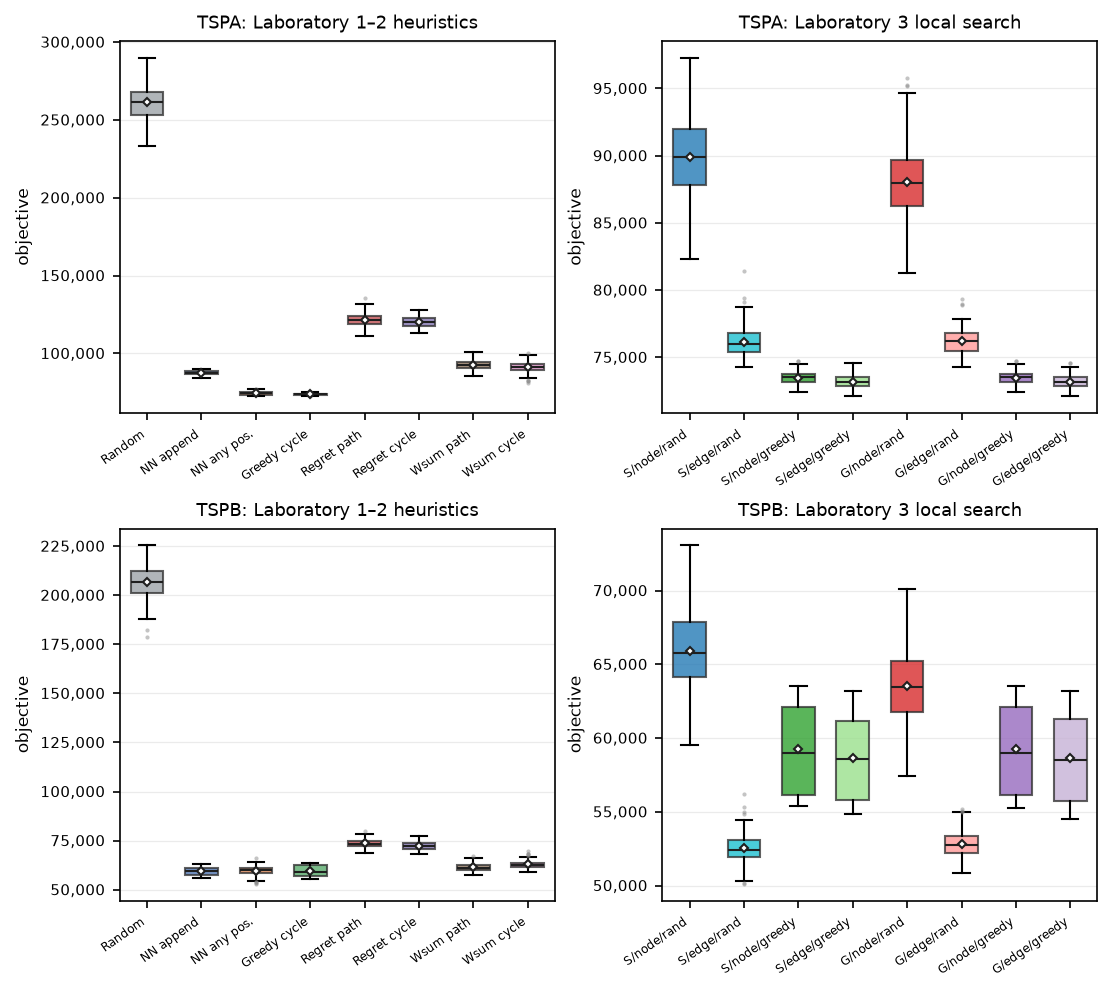

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(7.3, 6.5), layout="constrained")
groups = [
    (PREV, "Laboratory 1–2 heuristics"),
    (LS, "Laboratory 3 local search"),
]

for row, name in enumerate(INSTANCES):
    for col, (group, title) in enumerate(groups):
        ax = axes[row, col]
        data = [runs.loc[(runs.instance == name) & (runs.method == m),
                         "objective"].to_numpy() for m in group]
        bp = ax.boxplot(
            data, tick_labels=[SHORT[m] for m in group], widths=0.6,
            patch_artist=True, showmeans=True,
            medianprops=dict(color="#1f1f1f", lw=1.0),
            meanprops=dict(marker="D", markerfacecolor="white",
                           markeredgecolor="#1f1f1f", markersize=3.0),
            flierprops=dict(marker="o", markersize=2.0, markerfacecolor="#8a8a8a",
                            markeredgecolor="none", alpha=0.5),
        )
        for patch, method in zip(bp["boxes"], group):
            patch.set_facecolor(COLORS[method])
            patch.set_alpha(0.78)
            patch.set_edgecolor("#333333")
        ax.set_title(f"{name}: {title}", fontsize=8.5)
        ax.set_ylabel("objective", fontsize=8)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.grid(axis="y", alpha=0.25, lw=0.6)
        ax.set_axisbelow(True)
        ax.set_xticklabels([SHORT[m] for m in group], rotation=35, ha="right",
                           fontsize=5.8)
        ax.tick_params(axis="y", labelsize=7)

fig.savefig(FIG / "distributions.png", bbox_inches="tight")
plt.show()

The distributions separate into three groups: the random heuristic (far
right and very wide), the regret/weighted heuristics (also wide), and the
local-search methods (narrow and low). Among the local-search methods, the
edge-exchange variants are clearly better than the node-exchange variants, and
the greedy-start edge-exchange methods produce the tightest TSPA distribution.
On TSPB the random-start edge-exchange method is remarkably strong: its whole
distribution lies below the greedy-start distributions.

## 6. Local-search diagnostics

The table below reports, for each local-search method and instance, the average
starting objective, the average final objective, the relative improvement, the
average number of accepted moves and the average number of evaluated deltas.
It demonstrates both that the search really improves the start and that the
greedy version evaluates far fewer deltas than the steepest version.

In [7]:
ls_runs = runs[runs.method.isin(LS)].copy()
diag = ls_runs.groupby(["instance", "method"]).agg(
    initial=("initial_objective", "mean"),
    final=("objective", "mean"),
    moves=("moves", "mean"),
    evaluated=("evaluated", "mean"),
).reset_index()
diag["improvement"] = 100.0 * (diag["initial"] - diag["final"]) / diag["initial"]

for name in INSTANCES:
    d = diag[diag.instance == name].set_index("method").reindex(LS)
    d.index = [SHORT[m] for m in d.index]
    d = d.rename(columns={
        "initial": "Initial", "final": "Final",
        "improvement": "Improvement %", "moves": "Accepted moves",
        "evaluated": "Evaluated deltas",
    })
    display(d.style.format({
        "Initial": "{:,.1f}", "Final": "{:,.1f}",
        "Improvement %": "{:.2f}", "Accepted moves": "{:.2f}",
        "Evaluated deltas": "{:,.0f}",
    }).set_caption(f"{name}: local-search effort and improvement"))

,instance,Initial,Final,Accepted moves,Evaluated deltas,Improvement %
S/node/rand,TSPA,"261,727.8","89,919.7",154.88,"2,330,331",65.64
S/edge/rand,TSPA,"260,444.7","76,124.2",132.63,"1,984,406",70.77
S/node/greedy,TSPA,"73,793.4","73,472.4",3.10,"61,370",0.43
S/edge/greedy,TSPA,"73,793.4","73,178.6",5.85,"101,722",0.83
G/node/rand,TSPA,"262,591.9","88,037.0",420.40,"143,427",66.47
G/edge/rand,TSPA,"261,975.6","76,189.2",415.94,"96,606",70.92
G/node/greedy,TSPA,"73,793.4","73,474.0",3.54,"33,227",0.43
G/edge/greedy,TSPA,"73,793.4","73,173.2",7.39,"44,819",0.84


,instance,Initial,Final,Accepted moves,Evaluated deltas,Improvement %
S/node/rand,TSPB,"206,970.3","65,908.2",152.56,"2,295,797",68.16
S/edge/rand,TSPB,"206,225.5","52,514.1",133.34,"1,994,875",74.54
S/node/greedy,TSPB,"59,649.9","59,232.6",6.37,"110,107",0.70
S/edge/greedy,TSPB,"59,649.9","58,666.1",10.47,"170,404",1.65
G/node/rand,TSPB,"206,220.4","63,557.4",416.62,"137,149",69.18
G/edge/rand,TSPB,"206,700.2","52,845.9",421.58,"96,905",74.43
G/node/greedy,TSPB,"59,649.9","59,237.0",7.15,"43,553",0.69
G/edge/greedy,TSPB,"59,649.9","58,653.1",13.08,"54,103",1.67


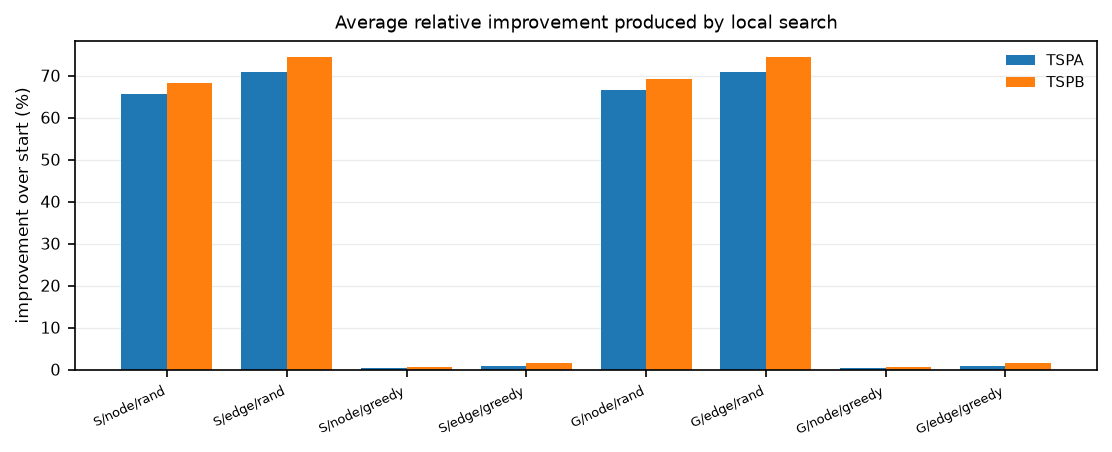

In [8]:
fig, ax = plt.subplots(figsize=(7.3, 2.9), layout="constrained")
x = np.arange(len(LS))
width = 0.38
for offset, name in zip((-width / 2, width / 2), INSTANCES):
    vals = [diag[(diag.instance == name) & (diag.method == m)]["improvement"].iloc[0]
            for m in LS]
    ax.bar(x + offset, vals, width, label=name)
ax.set_xticks(x)
ax.set_xticklabels([SHORT[m] for m in LS], rotation=25, ha="right", fontsize=6.2)
ax.set_ylabel("improvement over start (%)")
ax.set_title("Average relative improvement produced by local search")
ax.legend(frameon=False, fontsize=7)
ax.grid(axis="y", alpha=0.25, lw=0.6)
ax.set_axisbelow(True)
fig.savefig(FIG / "diagnostics.png", bbox_inches="tight")
plt.show()

All methods improve their starting solution, but the scale of the improvement
depends mainly on the starting solution. From the strong greedy-cycle start the
local search gains less than two percent: it mainly repairs a few expensive
edges. From a random start it removes about two thirds to three quarters of the
objective, which is still not enough to beat the best greedy-start variants on
TSPA, although it wins on TSPB. The greedy version usually accepts more, smaller
moves but evaluates far fewer deltas: about twenty times fewer for the
random-start edge variants and two to three times fewer from the greedy cycle.

## 7. Best solutions

Each panel shows the best cycle found by one method. Grey dots are nodes that
were **not** selected. Selected nodes are drawn with a colour **and** a radius
that both encode the node cost (dark purple, small = cheap; yellow, large =
expensive). Thin arrows show the direction of travel along the cycle.

In [9]:
CMAP = plt.get_cmap("viridis")

def load_tour(name, method):
    row = tours[(tours.instance == name) & (tours.method == method)].iloc[0]
    return np.array([int(v) for v in str(row["tour"]).split()]), row

def draw(ax, name, method, norm, short=True):
    df = COORDS[name]
    tour, row = load_tour(name, method)
    sel = np.zeros(len(df), dtype=bool)
    sel[tour] = True
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    cost = df.cost.to_numpy()

    ax.scatter(x[~sel], y[~sel], s=5, c="#d4d4d4", linewidths=0, zorder=1)
    for i in range(len(tour)):
        a, b = tour[i], tour[(i + 1) % len(tour)]
        ax.annotate("", xy=(x[b], y[b]), xytext=(x[a], y[a]),
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=0.42,
                                    shrinkA=2.0, shrinkB=3.0, mutation_scale=5,
                                    alpha=0.75),
                    zorder=2)
    t = (cost[tour] - norm.vmin) / max(1e-9, norm.vmax - norm.vmin)
    ax.scatter(x[tour], y[tour], s=7 + 42 * t, c=cost[tour], cmap=CMAP,
               norm=norm, edgecolors="#1b1b1b", linewidths=0.35, zorder=3)

    label = SHORT[method] if short else LABELS[method]
    ax.set_title(f"{label}\nobjective {nf(row['objective'])}",
                 fontsize=6.9 if short else 7.8, pad=3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#dcdcdc")

def best_figure(name):
    norm = mpl.colors.Normalize(*COST_RANGE[name])
    ncol = 4
    nrow = (len(METHODS) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.3, 1.95 * nrow),
                             layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, method in zip(axes, METHODS):
        draw(ax, name, method, norm)
    for ax in axes[len(METHODS):]:
        ax.axis("off")
    fig.suptitle(f"{name}: best solution found by each method", fontsize=10)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=list(axes), fraction=0.022, pad=0.015)
    cb.set_label("node cost", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    fig.savefig(FIG / f"best_{name}.png", bbox_inches="tight")
    plt.show()

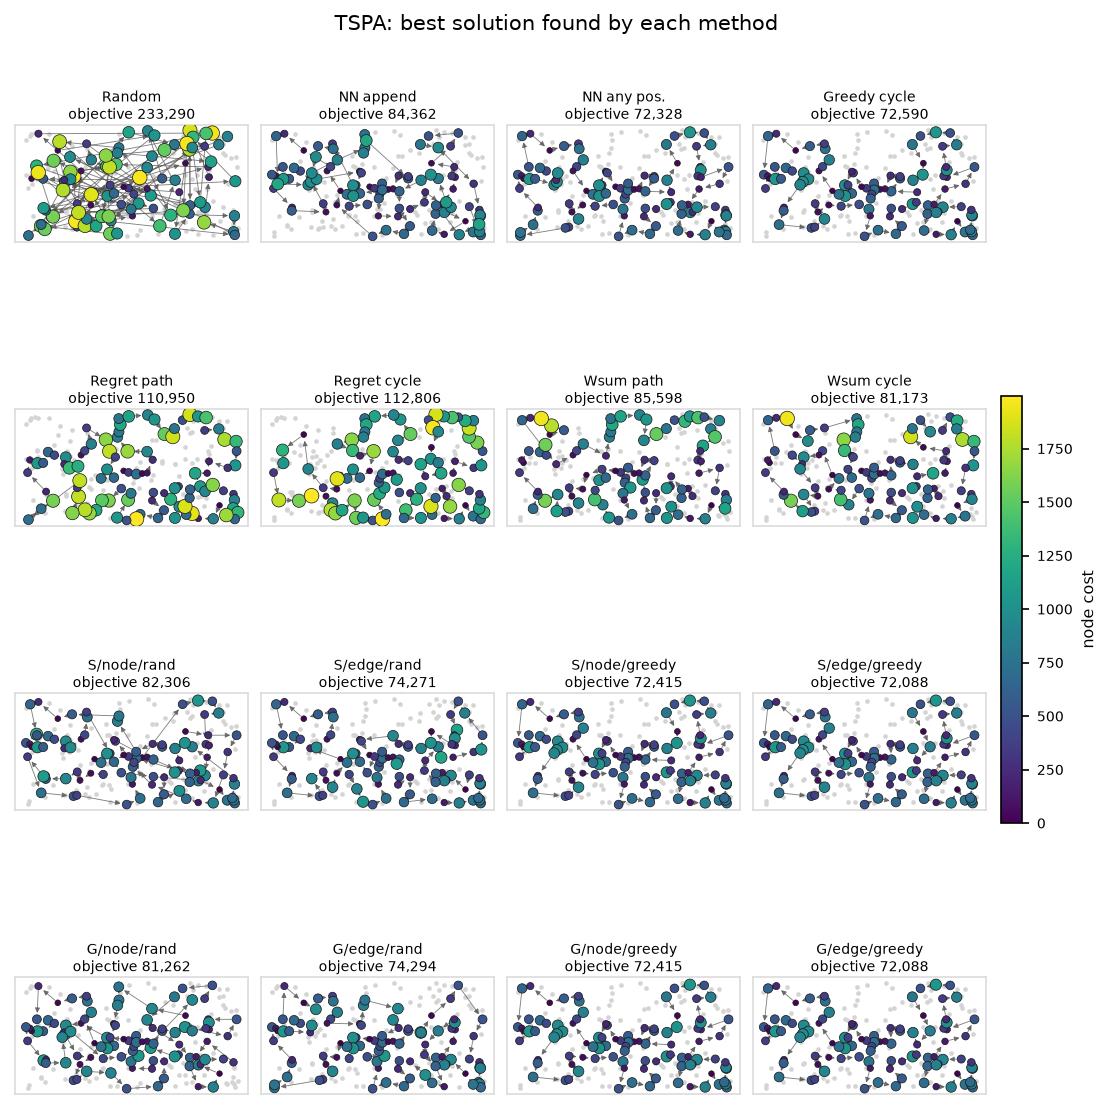

In [10]:
best_figure("TSPA")

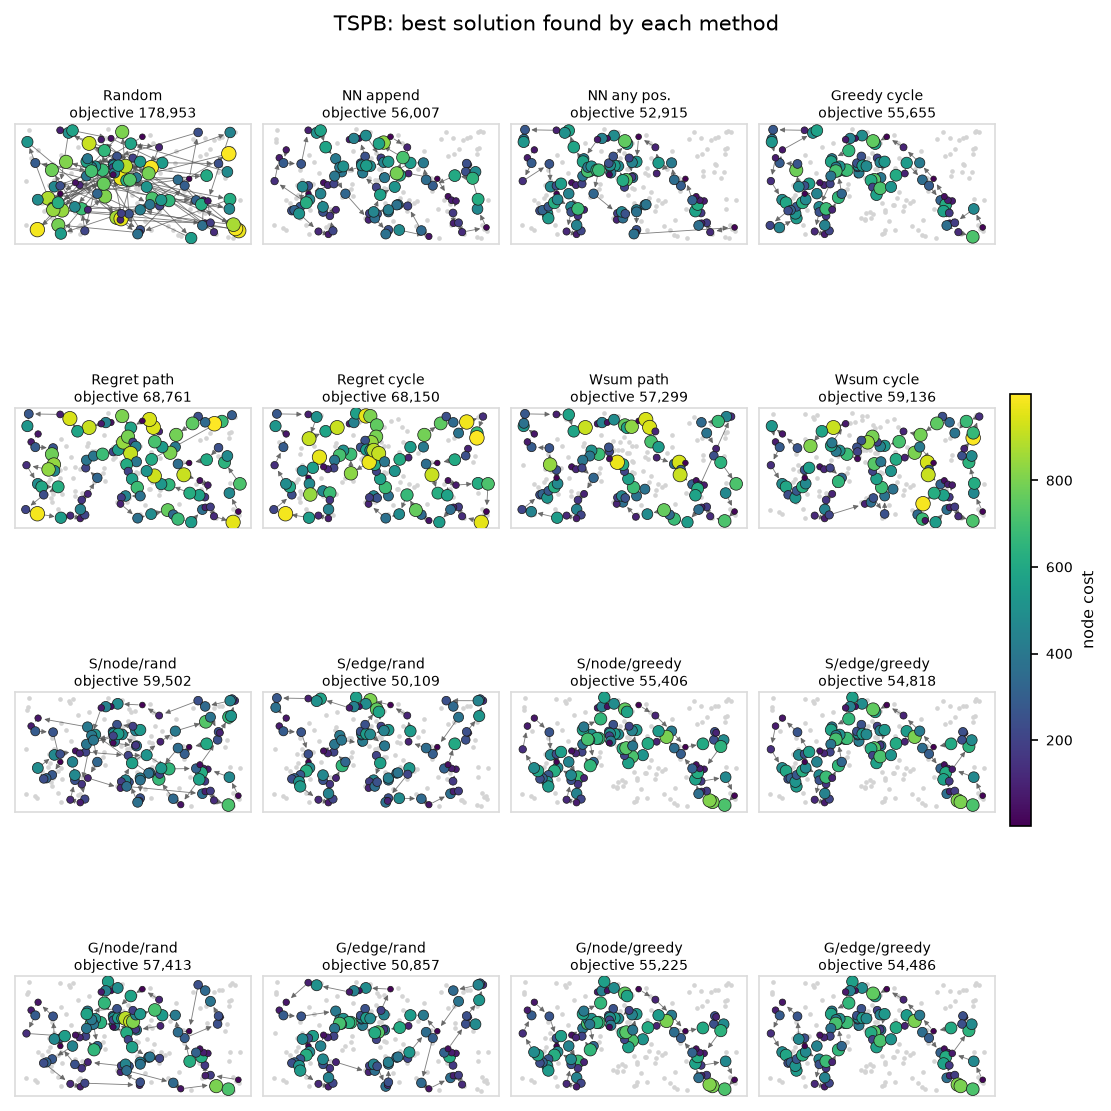

In [11]:
best_figure("TSPB")

## 8. Best solutions as node lists

All indices are **0-based**; the list is the cycle order and the closing arc runs
from the last node back to the first one. For spreadsheet use,
`lab3/results/best_tours_columns.csv` stores all 32 tours as columns: every
column contains 100 node indices, one per row, so it can be copied directly into
Excel without reformatting. Every stored solution is also independently
re-evaluated by the engine's `evaluate()` routine.

In [12]:
for name in INSTANCES:
    print(name)
    for method in METHODS:
        _, row = load_tour(name, method)
        idx = str(row["tour"]).split()
        print(f"\n{LABELS[method]} — objective {nf(row['objective'])} "
              f"(distance {nf(row['distance'])}, costs {nf(row['costs'])}), "
              f"first node {int(row['first_node'])}:")
        for i in range(0, len(idx), 16):
            print("  " + " ".join(idx[i:i + 16]))
    print()

TSPA

Random — objective 233,290 (distance 134,993, costs 98,297), first node 111:
  111 151 38 99 54 39 174 144 1 133 30 55 101 180 2 68
  102 83 80 154 104 175 186 120 60 185 74 62 198 132 196 22
  94 44 173 27 110 187 170 193 124 50 197 150 56 98 25 191
  35 143 65 112 137 20 8 90 49 113 67 66 12 37 24 166
  135 48 79 82 63 45 123 189 78 4 157 36 10 167 141 127
  41 84 40 73 96 139 59 195 0 70 184 43 19 178 34 18
  69 53 95 164

NN (append at end) — objective 84,362 (distance 31,319, costs 53,043), first node 54:
  54 9 33 36 177 67 144 53 135 58 134 176 174 106 89 107
  57 182 151 93 50 3 1 164 178 29 136 186 184 47 159 130
  153 78 88 193 170 146 75 64 150 42 113 43 85 142 8 131
  84 158 192 181 114 141 180 132 76 80 48 31 63 149 168 97
  127 187 30 123 152 108 60 116 49 11 119 160 83 90 51 16
  35 87 45 140 52 179 185 28 102 156 157 71 91 38 100 4
  112 139 115 5

NN (any position) — objective 72,328 (distance 21,816, costs 50,512), first node 104:
  104 129 69 127 97 168 116 149

## 9. Observations

In [13]:
import textwrap

from IPython.display import Markdown

stats = runs.groupby(["instance", "method"]).agg(
    mean=("objective", "mean"),
    std=("objective", "std"),
    dist=("distance", "mean"),
    cost=("costs", "mean"),
).reset_index()

def st(name, method, column):
    row = stats[(stats.instance == name) & (stats.method == method)]
    return row.iloc[0][column]

def pct(a, b):
    return 100.0 * (b - a) / a

def nr(v):
    return f"{round(v):,}"

def ev(name, method):
    row = diag[(diag.instance == name) & (diag.method == method)]
    return row.iloc[0]["evaluated"]

items = []

for name in INSTANCES:
    best_prev = min(PREV, key=lambda m: st(name, m, "mean"))
    best_ls = min(LS, key=lambda m: st(name, m, "mean"))
    gain = abs(pct(st(name, best_prev, "mean"), st(name, best_ls, "mean")))
    items.append(
        f"{name}: the best average local-search result is {SHORT[best_ls]} at "
        f"{nr(st(name, best_ls, 'mean'))}, compared with "
        f"{nr(st(name, best_prev, 'mean'))} for the best previous heuristic "
        f"({SHORT[best_prev]}), an improvement of {gain:.2f}%. "
        f"The best single solution is {nr(summary[summary.instance == name]['best'].min())}."
    )

for name in INSTANCES:
    best_node = min(st(name, m, "mean") for m in LS if "nodes" in m)
    best_edge = min(st(name, m, "mean") for m in LS if "edges" in m)
    gain = abs(pct(best_node, best_edge))
    items.append(
        f"On {name}, the best edge-exchange variant is {gain:.1f}% below the best "
        f"node-exchange variant. Two-edge exchange changes the route geometry much more "
        f"strongly than swapping two nodes, while both keep the selected set fixed."
    )

for name in INSTANCES:
    s_edge_g = st(name, "ls_steepest_edges_greedy", "mean")
    g_edge_g = st(name, "ls_greedy_edges_greedy", "mean")
    s_edge_r = st(name, "ls_steepest_edges_random", "mean")
    g_edge_r = st(name, "ls_greedy_edges_random", "mean")
    items.append(
        f"On {name}, steepest and greedy edge search are practically tied from the "
        f"greedy start ({nr(s_edge_g)} vs {nr(g_edge_g)}) and from the random start "
        f"({nr(s_edge_r)} vs {nr(g_edge_r)}). The random-start variants evaluate "
        f"{ev(name, 'ls_steepest_edges_random'):,.0f} deltas for steepest and "
        f"{ev(name, 'ls_greedy_edges_random'):,.0f} for greedy; the greedy scan stops "
        f"at the first improving move, so it does much less work for the same quality."
    )

for name in INSTANCES:
    rand_edge = st(name, "ls_steepest_edges_random", "mean")
    greedy_edge = st(name, "ls_steepest_edges_greedy", "mean")
    if rand_edge < greedy_edge:
        verdict = (
            "the random start is better; the greedy cycle leads the search into a "
            "strong local optimum that the mixed neighbourhood cannot escape"
        )
    else:
        verdict = (
            "the greedy start is better; the random tour improves dramatically but "
            "ends in a worse local optimum"
        )
    items.append(
        f"The starting solution matters on {name}: edge search from a random start "
        f"averages {nr(rand_edge)}, while from the greedy cycle it averages "
        f"{nr(greedy_edge)} — {verdict}."
    )

ms = summary.groupby("method")["time_ms"].mean() / RUNS
heuristic_ms = [ms[m] for m in PREV]
greedy_start_ms = [ms[m] for m in LS if m.endswith("_greedy")]
random_start_ms = [ms[m] for m in LS if m.endswith("_random")]
slowest = max(ms.index, key=ms.get)
items.append(
    "Cost per run: the one-shot heuristics take "
    f"{min(heuristic_ms):.2f}–{max(heuristic_ms):.2f} ms; local search from a "
    f"greedy start takes {min(greedy_start_ms):.2f}–{max(greedy_start_ms):.2f} ms, "
    f"and from a random start {min(random_start_ms):.2f}–"
    f"{max(random_start_ms):.2f} ms. The slowest method is {SHORT[slowest]} at "
    f"{ms[slowest]:.2f} ms per run."
)

bullets = "\n".join(
    textwrap.fill(item, width=88, initial_indent="- ", subsequent_indent="  ")
    for item in items
)
display(Markdown(bullets))


- TSPA: the best average local-search result is G/edge/greedy at 73,173, compared with
  73,793 for the best previous heuristic (Greedy cycle), an improvement of 0.84%. The
  best single solution is 72,088.
- TSPB: the best average local-search result is S/edge/rand at 52,514, compared with
  59,397 for the best previous heuristic (NN append), an improvement of 11.59%. The best
  single solution is 50,109.
- On TSPA, the best edge-exchange variant is 0.4% below the best node-exchange variant.
  Two-edge exchange changes the route geometry much more strongly than swapping two
  nodes, while both keep the selected set fixed.
- On TSPB, the best edge-exchange variant is 11.3% below the best node-exchange variant.
  Two-edge exchange changes the route geometry much more strongly than swapping two
  nodes, while both keep the selected set fixed.
- On TSPA, steepest and greedy edge search are practically tied from the greedy start
  (73,179 vs 73,173) and from the random start (76,124 vs 76,189). The random-start
  variants evaluate 1,984,406 deltas for steepest and 96,606 for greedy; the greedy scan
  stops at the first improving move, so it does much less work for the same quality.
- On TSPB, steepest and greedy edge search are practically tied from the greedy start
  (58,666 vs 58,653) and from the random start (52,514 vs 52,846). The random-start
  variants evaluate 1,994,875 deltas for steepest and 96,905 for greedy; the greedy scan
  stops at the first improving move, so it does much less work for the same quality.
- The starting solution matters on TSPA: edge search from a random start averages
  76,124, while from the greedy cycle it averages 73,179 — the greedy start is better;
  the random tour improves dramatically but ends in a worse local optimum.
- The starting solution matters on TSPB: edge search from a random start averages
  52,514, while from the greedy cycle it averages 58,666 — the random start is better;
  the greedy cycle leads the search into a strong local optimum that the mixed
  neighbourhood cannot escape.
- Cost per run: the one-shot heuristics take 0.00–1.89 ms; local search from a greedy
  start takes 2.55–2.95 ms, and from a random start 11.96–32.50 ms. The slowest method
  is G/node/rand at 32.50 ms per run.

**Discussion.** The local-search results confirm that the choice of intra-route
move matters more than the choice between steepest and greedy scanning. Two-edge
exchange is clearly the stronger neighbourhood: it can repair a long detour in
one move, whereas a node swap only moves two selected points. The same pattern
appears with both starting solutions and on both instances.

The starting solution determines how much the local search can gain. From the
greedy cycle the improvement is small in relative terms, but the resulting
tours are the best on TSPA. From a random start the search improves the objective
dramatically but usually ends in a worse local optimum on TSPA; on TSPB the
random-start edge search is better than the greedy-start one, which shows that
the greedy cycle can lead into a local optimum with no improving move from the
mixed neighbourhood. This is also why the best single TSPB solution comes from
the random-start edge variant.

Steepest and greedy scanning reach almost the same final values. The greedy
version uses much less work on average because it stops at the first improving
move; the final unsuccessful scan still browses the whole neighbourhood, so the
total cost depends on how early improvements are found. Overall, the best
quality/time compromise in this experiment is greedy edge exchange from the
greedy cycle on TSPA, and steepest edge exchange from random starts on TSPB.

## 10. Reproduction

The engine and the report tooling are shared by all laboratories and live at the
repository root. The Lab-3 notebook can be executed on its own; it builds the
engine and reruns the complete experiment.

```bash
# 1. Python environment (once, at the repository root)
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt

# 2. Build the shared engine
make

# 3. Execute this notebook, export HTML and print the PDF
.venv/bin/python tools/render_report.py lab3
```

`./run.sh lab3` performs all of these steps. The engine writes
`lab3/results/summary.csv`, `lab3/results/runs.csv`,
`lab3/results/best_tours.csv` and `lab3/results/best_tours_columns.csv`; this
notebook writes the figures to `lab3/report/figures/` and the exported report to
`lab3/report/report.html` and `lab3/report/report.pdf`.